# Sensitivity

This notebook re-reads the recorded base-case books under the design in `configs/sensitivity.yaml`. It reruns no backtest, doesn't re-solve the optimiser and chooses no book. The evaluation window, 2014-01-02 onwards, is primary.

Results are read from `reports/sensitivity/`, and the summary is in `reports/sensitivity/SUMMARY.md`.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

OUT = Path("../reports/sensitivity")
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)
read = lambda name: pd.read_csv(OUT / f"{name}.csv")

GROSS, NET = "#2a78d6", "#eb6834"
SIGNALS = ["lightgbm_h5_rank", "B0_reversal_h5", "B1_composite_h5", "lightgbm_h21_rank"]
CONSTRUCTIONS = ["decile_ls", "neutral_volscaled", "optimised"]
BOOKS = [(s, c) for c in CONSTRUCTIONS for s in SIGNALS]
NAMES = [f"{s}, {c}" for s, c in BOOKS]
SHOWN = {("lightgbm_h5_rank", "optimised"): "#2a78d6", ("lightgbm_h5_rank", "neutral_volscaled"): "#eb6834",
         ("B0_reversal_h5", "optimised"): "#1baf7a", ("B1_composite_h5", "neutral_volscaled"): "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
meta = json.loads((OUT / "run_metadata.json").read_text())
display(read("checks").groupby("check").agg(rows=("passed", "size"), all_passed=("passed", "all"), largest_value=("value", "max")))
{k: meta[k] for k in ("code_commit", "code_dirty", "holdout_start")}

,rows,all_passed,largest_value
check,,,
last_date_before_holdout,12,True,0.000000e+00
paired_dates,6,True,0.000000e+00
reprice_base,12,True,4.163336e-17
reproduce_sharpes,24,True,1.110223e-16
tranches_sum,12,True,2.775558e-17


{'code_commit': '62b3c1a259ef0280df5fbe9810d09cb0d9a8804b',
 'code_dirty': False,
 'holdout_start': '2022-01-01'}

## The two declared intervals

Both contain zero. The headline net Sharpe is -0.00 with a 95% interval of -0.60 to +0.62, and LightGBM minus B0 under `optimised` is +0.02 with an interval of -0.96 to +1.07. An interval this wide doesn't show that the edge is zero. It shows that an 8-year window can't separate zero from a net Sharpe of about 0.5.

In [2]:
display(read("primary_intervals").T)

,0,1
interval,headline,lightgbm_minus_b0
estimate,-0.001464,0.024523
ci_low,-0.603165,-0.957822
ci_high,0.616964,1.068197
resample_sd,0.310523,0.516982
share_above_zero,0.4902,0.5163
contains_zero,True,True
n_days,1999,1999
mean_block_length,21,21


## All 12 books

Only three of the 24 evaluation-window intervals exclude zero: the gross `neutral_volscaled` LightGBM book (0.20 to 1.42), and the net B0 `decile_ls` and `neutral_volscaled` books, which are clearly negative. These are descriptive, with no multiple-testing correction.

mean_block_length
21    0.338
42    0.317
63    0.310
Name: resample_sd, dtype: float64

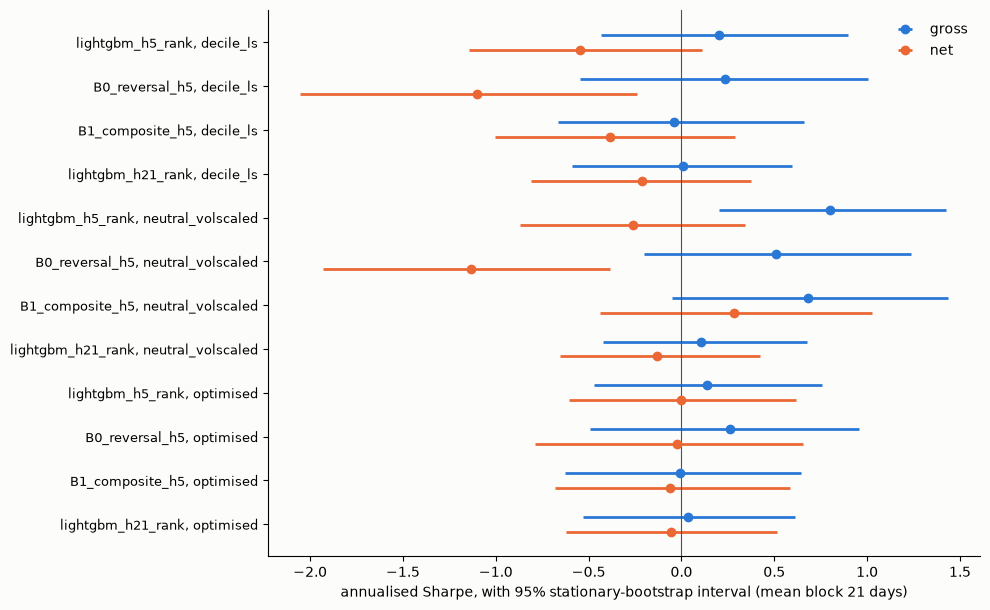

In [3]:
boot = read("bootstrap_intervals").query("window == 'evaluation' and mean_block_length == 21").set_index(["signal", "construction", "series"])
fig, ax = plt.subplots(figsize=(10, 6.2))
for offset, (series, color, name) in zip((-0.17, 0.17), (("gross_pnl", GROSS, "gross"), ("net_pnl", NET, "net"))):
    s = boot.xs(series, level="series").loc[BOOKS]
    y = np.arange(len(BOOKS)) + offset
    ax.errorbar(s["sharpe"], y, xerr=[s["sharpe"] - s["ci_low"], s["ci_high"] - s["sharpe"]], fmt="o", ms=6, lw=2, color=color, label=name)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(range(len(BOOKS)), NAMES, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("annualised Sharpe, with 95% stationary-bootstrap interval (mean block 21 days)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "sharpe_intervals.png", dpi=150)
display(read("bootstrap_intervals").query("window == 'evaluation'").groupby("mean_block_length")["resample_sd"].mean().round(3))

Block length barely matters. The mean resample sd falls slightly as blocks get longer, from 0.34 to 0.31, so these returns have no positive serial dependence that the 21-day block was missing.

## LightGBM minus B0

The `neutral_volscaled` net difference of +0.87 excludes zero (0.15 to 1.68), but that isn't evidence of skill: both books lose money net, and the gross difference of +0.29 doesn't exclude zero. Most of the gap appears only after costs, and B0 trades 72× a year against LightGBM's 54×.

In [4]:
diff = read("paired_differences").query("window == 'evaluation' and mean_block_length == 21")
display(diff[["construction", "series", "difference", "ci_low", "ci_high", "share_above_zero", "contains_zero"]].round(2))

,construction,series,difference,ci_low,ci_high,share_above_zero,contains_zero
0,decile_ls,gross_pnl,-0.04,-0.75,0.76,0.48,True
1,neutral_volscaled,gross_pnl,0.29,-0.49,1.08,0.76,True
2,optimised,gross_pnl,-0.13,-1.10,0.91,0.40,True
3,decile_ls,net_pnl,0.55,-0.13,1.42,0.94,True
4,neutral_volscaled,net_pnl,0.87,0.15,1.68,0.99,False
5,optimised,net_pnl,0.02,-0.96,1.07,0.52,True


## Y and borrow, with trades held fixed

Each book is repriced at its recorded trades, so `optimised` isn't re-solved. The left panel moves Y with borrow at 25 bp, and the right panel moves borrow with Y at 1.

The headline book hardly reacts to Y but falls steadily with borrow. LightGBM `neutral_volscaled` is the reverse. Across the whole grid, no book reaches a net t of 2: the largest is 1.30.

,signal,construction,window,breakeven_impact_y,breakeven_borrow_bps_per_year
0,lightgbm_h5_rank,decile_ls,evaluation,0.05,-1059.24
2,lightgbm_h5_rank,neutral_volscaled,evaluation,0.61,-169.90
4,lightgbm_h5_rank,optimised,evaluation,0.94,24.59
6,B0_reversal_h5,decile_ls,evaluation,-0.03,-1895.41
8,B0_reversal_h5,neutral_volscaled,evaluation,-0.02,-798.38
10,B0_reversal_h5,optimised,evaluation,0.86,6.36
12,B1_composite_h5,decile_ls,evaluation,-0.49,-1007.54
14,B1_composite_h5,neutral_volscaled,evaluation,2.30,297.95
16,B1_composite_h5,optimised,evaluation,-1.99,-40.46
18,lightgbm_h21_rank,decile_ls,evaluation,-0.36,-330.52


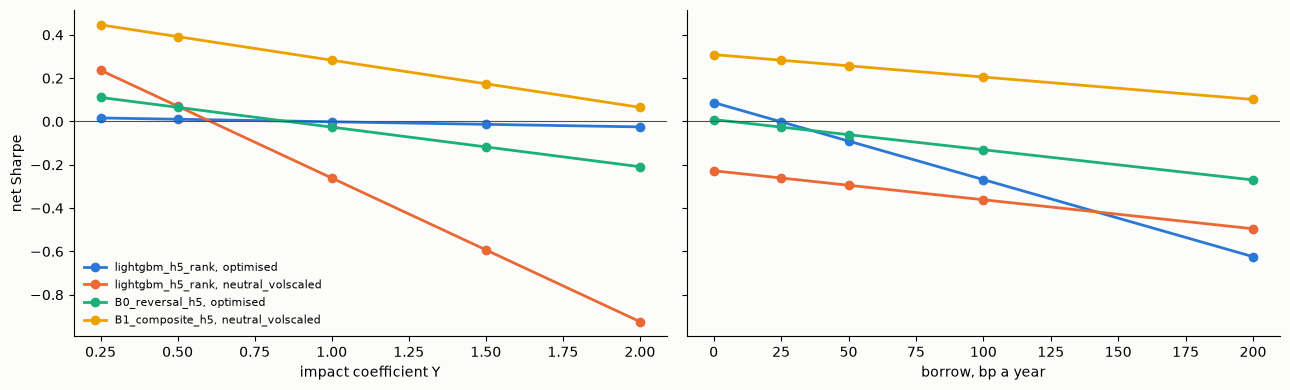

In [5]:
grid = read("repricing_grid").query("window == 'evaluation'")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for (signal, construction), color in SHOWN.items():
    g = grid[(grid["signal"] == signal) & (grid["construction"] == construction)]
    a = g[g["borrow_bps_per_year"] == 25].sort_values("impact_y")
    b = g[g["impact_y"] == 1].sort_values("borrow_bps_per_year")
    axes[0].plot(a["impact_y"], a["net_sharpe"], marker="o", lw=2, ms=6, color=color, label=f"{signal}, {construction}")
    axes[1].plot(b["borrow_bps_per_year"], b["net_sharpe"], marker="o", lw=2, ms=6, color=color)
for ax in axes:
    ax.axhline(0, color="#52514e", lw=0.8)
axes[0].set_xlabel("impact coefficient Y")
axes[1].set_xlabel("borrow, bp a year")
axes[0].set_ylabel("net Sharpe")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "repricing.png", dpi=150)
display(read("repricing_breakeven").query("window == 'evaluation'").round(2))

## Offsets

Each dot is one rebalance offset's net Sharpe, and the cross is the book's total. Reversal is the most offset-sensitive signal. B0 `optimised` runs from -0.27 to +0.21 net, so with a single offset the same book could look positive or negative. Turnover is the same across offsets.

A total can sit at the edge of its offsets, or outside the middle of them, because averaging offsets cuts volatility, which scales the Sharpe up in either direction.

/var/folders/w0/zqfpt_0d647_mfxzl6pzl6b40000gp/T/ipykernel_30356/2675916988.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax.plot(off.loc[book, "sharpe"], np.full(len(off.loc[book]), i), "o", ms=5, color=NET, alpha=0.6)
/var/folders/w0/zqfpt_0d647_mfxzl6pzl6b40000gp/T/ipykernel_30356/2675916988.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax.plot(off.loc[book, "sharpe"], np.full(len(off.loc[book]), i), "o", ms=5, color=NET, alpha=0.6)


,signal,construction,series,n_offsets,total,min,max,range,sd
1,lightgbm_h5_rank,decile_ls,gross_pnl,5,0.20,0.14,0.29,0.14,0.06
4,lightgbm_h5_rank,decile_ls,net_pnl,5,-0.55,-0.55,-0.41,0.14,0.06
13,lightgbm_h5_rank,neutral_volscaled,gross_pnl,5,0.80,0.66,0.82,0.16,0.06
16,lightgbm_h5_rank,neutral_volscaled,net_pnl,5,-0.26,-0.34,-0.17,0.17,0.07
25,lightgbm_h5_rank,optimised,gross_pnl,5,0.14,0.05,0.22,0.18,0.08
28,lightgbm_h5_rank,optimised,net_pnl,5,-0.00,-0.09,0.09,0.18,0.08
37,B0_reversal_h5,decile_ls,gross_pnl,5,0.24,-0.04,0.51,0.55,0.24
40,B0_reversal_h5,decile_ls,net_pnl,5,-1.10,-1.14,-0.63,0.51,0.24
49,B0_reversal_h5,neutral_volscaled,gross_pnl,5,0.51,0.23,0.57,0.34,0.13
52,B0_reversal_h5,neutral_volscaled,net_pnl,5,-1.13,-1.14,-0.84,0.30,0.11


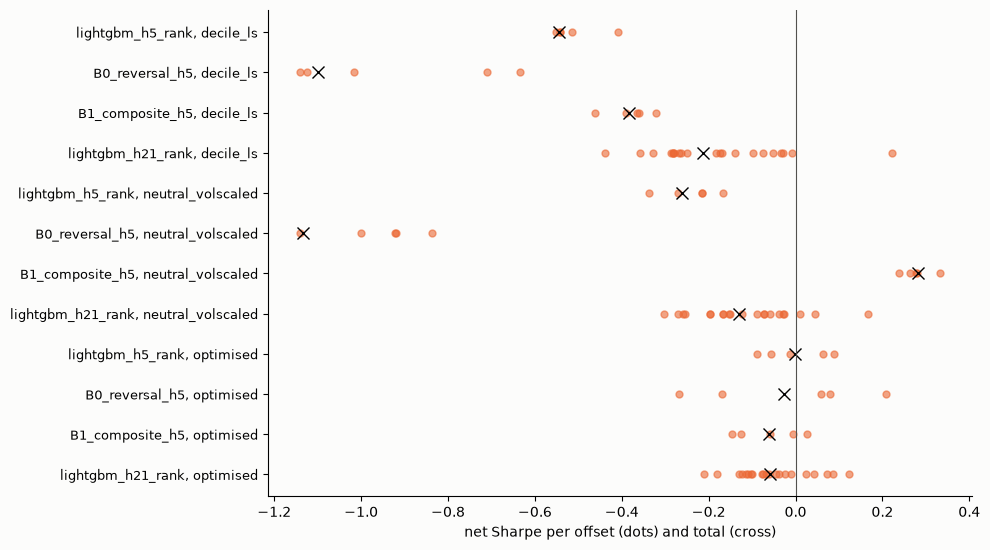

In [6]:
off = read("offsets").query("window == 'evaluation' and series == 'net_pnl'").set_index(["signal", "construction"])
disp = read("offset_dispersion").query("window == 'evaluation' and series == 'net_pnl' and statistic == 'sharpe'").set_index(["signal", "construction"])
fig, ax = plt.subplots(figsize=(10, 5.6))
for i, book in enumerate(BOOKS):
    ax.plot(off.loc[book, "sharpe"], np.full(len(off.loc[book]), i), "o", ms=5, color=NET, alpha=0.6)
    ax.plot(disp.loc[book, "total"], i, "kx", ms=9)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(range(len(BOOKS)), NAMES, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("net Sharpe per offset (dots) and total (cross)")
fig.tight_layout()
fig.savefig(FIG / "offsets.png", dpi=150)
display(read("offset_dispersion").query("window == 'evaluation' and statistic == 'sharpe'")[
    ["signal", "construction", "series", "n_offsets", "total", "min", "max", "range", "sd"]].round(2))

## Conclusion

The null headline holds up, but it's a weak null. The data can't separate the headline from zero or from a modest positive or negative Sharpe, and no reasonable Y or borrow rate produces a significant net result. The one thing that stands apart is the gross `neutral_volscaled` LightGBM book, and costs are what stop it.